In [1]:
import os
import sys
sys.path.insert(0, "..")
sys.path.insert(0, os.path.join("..", "experiments"))
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rushhour import human_data as hd, paths, surrender as sr
import fit_memory as fm

SUMMARY = os.path.join(paths.MODELS, "summary")
INK, MUTED, RULE, GRID = "#1f1f1d", "#5f5e5a", "#b5b4ad", "#e6e5e0"
PEOPLE = "#1f1f1d"
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 110,
                     "legend.frameon": False, "legend.fontsize": 8})


def tidy(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)

# Teaching with Rush Hour Project, phase 2: how does the student plan? (11/19 - 11/22/26)

Phase 1 (`p1_summary.ipynb`) ended with a simulated student that starts where people do and learns at their rate,
which was enough to compare teachers. But that student only ever plays by **intuition**: one sample from its policy
network per move. AND-OR's backward reasoning (Olieslagers et al. 2023) taught it in pretraining and then disappeared.
People plan, and how they plan is what a teacher's help would have to fit into. Phase 2 asks:

1. **What would a planning student look like** - backward (AND-OR), forward (simulating moves ahead), or both?
2. **What makes a student human-like**, beyond the solve rate and moves / optimal that phase 1 fitted?
3. **How do people actually combine ways of choosing a move**, and does that change as they learn?

| Notebook | What it covers |
|---|---|
| `p2.1_deliberation.ipynb` | Backward planning alone: AND-OR ordered by the network, against people |
| `p2.2_forward_planning.ipynb` | Forward planning (novelty, relevance, the value head); forward + backward together; planners in the session; calibrating every planner to people's start; people's move times; a move-by-move mixture of modes; the lean student |
| `p2.3_human_likeness.ipynb` | People against the models move by move: optimal moves by distance, revisits, car roles, slides, timing; fitting a soft memory to people's revisits |

This notebook is the through-line: each section states the question, the answer, and where the evidence is. Its
figures are rebuilt from the saved results (`models/summary`, `models/sessions`; see `MODELS.md`).

## 1. Measuring humanness: what tells models apart

*(p2.3, sections 1-8)* Solve rate and moves / optimal can be matched by very different solvers. So people and every
candidate model were compared **move by move** on the 70 layouts people played: how often a move is optimal at each
distance from the goal, how often they return to an earlier board or undo, where moved cars land, which cars in the
AND-OR tree get moved, how far cars slide, and how long moves take.

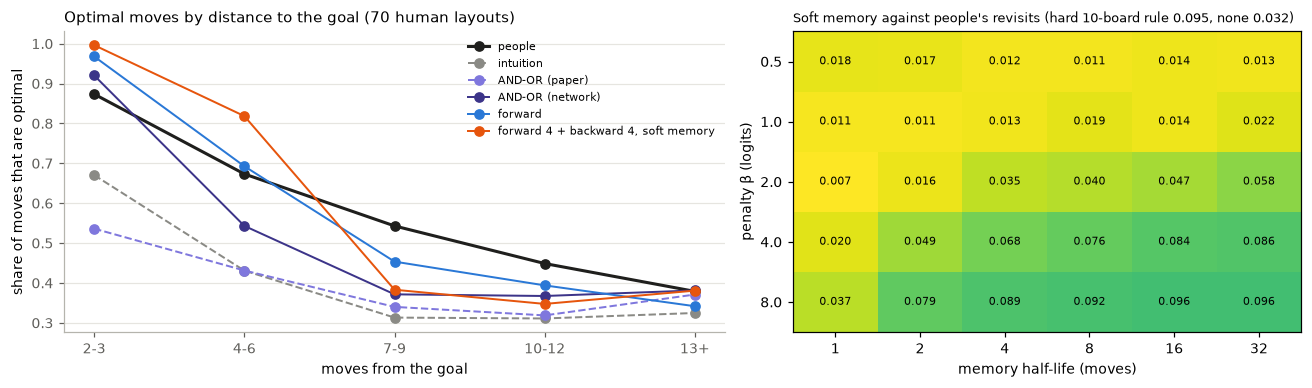

In [2]:
mv = pd.read_csv(os.path.join(SUMMARY, "human_profile", "moves.csv.gz"), dtype={"who": str},
                 usecols=["source", "distance", "after"])
mv = mv[mv.distance > 1]
mv["dist"] = pd.cut(mv.distance, [1, 3, 6, 9, 12, 99], labels=["2-3", "4-6", "7-9", "10-12", "13+"])
opt = (mv.after < mv.distance).groupby([mv.source, mv.dist], observed=True).mean().unstack()
SHOW = {"people": (PEOPLE, "-"), "intuition": ("#8a8a85", "--"), "AND-OR (paper)": ("#7f77dd", "--"),
        "AND-OR (network)": ("#3c3489", "-"), "forward": ("#2a78d6", "-"),
        "forward 4 + backward 4, soft memory": ("#e6550d", "-")}
mem, _ = fm.summarize(pd.read_csv(os.path.join(SUMMARY, "memory_fit.csv")), fm.people_target()[0]), None
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
for name, (color, style) in SHOW.items():
    axes[0].plot(range(5), opt.loc[name], style, marker="o", color=color, label=name, lw=2 if name == "people" else 1.3)
axes[0].set_xticks(range(5), opt.columns)
axes[0].set_xlabel("moves from the goal")
axes[0].set_ylabel("share of moves that are optimal")
axes[0].set_title("Optimal moves by distance to the goal (70 human layouts)")
axes[0].legend(fontsize=7)
tidy(axes[0])
grid_ = mem[mem.index.str.startswith("beta")].copy()
grid_["beta"] = grid_.index.str.extract(r"beta ([\d.]+)")[0].astype(float).values
grid_["half"] = grid_.index.str.extract(r"half-life (\d+)")[0].astype(int).values
h = grid_.pivot(index="beta", columns="half", values="misfit")
axes[1].imshow(h.values, cmap="viridis_r", vmax=0.3, aspect="auto")
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        axes[1].text(j, i, f"{h.values[i, j]:.3f}", ha="center", va="center", fontsize=7,
                     color="white" if h.values[i, j] > 0.15 else "black")
axes[1].set_xticks(range(h.shape[1]), h.columns)
axes[1].set_yticks(range(h.shape[0]), h.index)
axes[1].set_xlabel("memory half-life (moves)")
axes[1].set_ylabel("penalty β (logits)")
axes[1].set_title(f"Soft memory against people's revisits (hard 10-board rule {mem.loc['hard, last 10 boards', 'misfit']:.3f}, "
                  f"none {mem.loc['no memory', 'misfit']:.3f})", fontsize=8.5)
plt.tight_layout()
plt.show()

- **Most measures track efficiency.** At matched efficiency (solved attempts of 1.5-3 × optimal) every model makes
  optimal moves at about people's rate. What doesn't wash out is the *shape* by distance: people are better than
  every model in the middle of a puzzle, and the planners are too good near the goal (left).
- **People revisit and undo; the phase 1 student can't.** At matched efficiency people return to an earlier board on
  10% of moves and undo on 6%, like AND-OR. The intuition student's hard rule (never back to the last 10 boards)
  forbids both, and fits people's revisits worse than no memory at all (right).
- **People's memory is weak, not long**: the best replacement lowers a move back to a recent board by β = 2 logits
  fading with a 1-move half-life (an undo about 30-40% less likely). This **soft memory** is used by every model
  below. People also put cars back where they had been on 40% of moves, more than any model, and rarely move cars
  outside the AND-OR tree (4.4% of moves, against 14.6% of legal moves).

## 2. Backward planning alone

*(p2.1)* The most direct planning student is AND-OR itself, with the network ordering its options (the dest head, with
Gumbel noise) instead of choosing at random.

| on people's 70 layouts (first 10 trials) | solved | moves / optimal |
|---|---|---|
| people | 0.87 | about 2.8 |
| AND-OR ordered by the trained network (γ 0.035) | 0.70 | people's level on 10-15-move puzzles; ≈1.1 on 6-move (people 1.8) |
| plain AND-OR (random order), same γ | 0.63 | ≈3.5 |

- **Efficiency at people's level, solving not**: the long layouts defeat it (about 0.5 solved against people's 0.8 on
  13- and 15-move puzzles), and not because of giving up - with none it still solves only 0.77.
- **The network mostly buys efficiency**: ordering AND-OR's options cuts moves / optimal from ≈3.5 to ≈2.5.
- And from section 1, AND-OR's style is human in one way the intuition student isn't (it revisits and undoes), but
  it is too good near the goal. Backward planning alone is not the student.

## 3. Forward planning, then forward and backward together

*(p2.2, sections 1-2b)* A forward planner simulates short **rollouts** from the board with the policy and judges where
they end.

- **Novelty** (width-based planning: credit for car placements the attempt hasn't had) halves moves / optimal for
  every network; the dest head's **relevance** adds nothing, even with uniform proposals; the network's experience
  enters through the moves it **proposes**. The **value head** (predicted moves to go) is weak alone and useful as a
  tie-breaker.
- **But novelty is not human** (p2.3, section 9): people return cars to earlier spots constantly, which novelty
  forbids. Fitted to people's revisits, the planner wants no novelty - rollouts judged by the value head alone, with
  the soft memory.
- **Forward and backward complement each other**: 4 policy rollouts + 4 AND-OR passes, judged alike by the value head
  (best of 8), beat 8 of either kind for every network (start network: 4.88 moves / optimal against 5.27 and 5.31).
  Its excess undos came from fresh AND-OR passes; letting the memory judge the candidates fixes them (5.4% undos,
  9.6% returns; people 5.6%, 9.7%).
- **One lapse rate γ** for both directions fits as well as two, and the best γ falls over people's session (0.03 →
  0.01): deeper thought with practice, as van Opheusden et al. found. But γ cannot fix the **skill shape** (99%
  optimal near the goal against people's 87%; 31-43% mid-puzzle against 54%), and neither can giving the planner
  the networks the intuition session learned. Networks trained on the planner's own play help a little (53% optimal
  7-9 moves out by trials 46+, against 49%; people 59%).

## 4. Which planner can start where people do?

*(p2.2, section 2c)* The planner played in the session started near-optimal (1.44 moves / optimal against people's
2.76) and had nothing to learn. So every planner was calibrated to people's first 10 trials the way phase 1 chose its
start (`surrender.py`: the session's test puzzles at people's lengths, giving up applied at the session's scale).
Families: best of 8; forward rollouts alone; **flat** (Collins et al.'s novices: the policy's top few moves looked at
one move deep, a softmax over the value head's moves to go); flat + a checking rollout; **two modes** (flat, with an
AND-OR plan at an impasse); and the **lean student** (section 6).

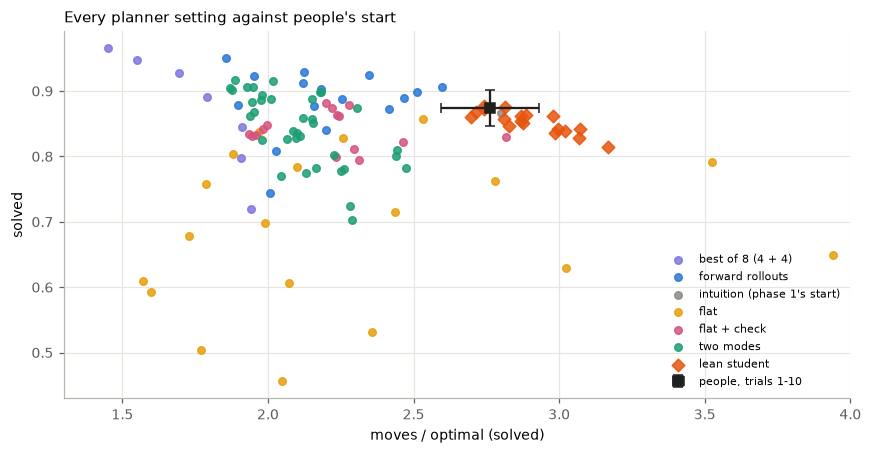

,config,solved,moves / optimal,misfit
family,,,,
lean student,lean flat 0.18 and-or 0.2,0.873,2.741,0.018
intuition (phase 1's start),"intuition, hard memory",0.867,2.801,0.115
flat,flat m3 tau 4,0.858,2.532,2.248
forward rollouts,forward k2 gamma 0.1,0.906,2.597,2.368
flat + check,flat+check m5 tau 4,0.830,2.819,2.684
two modes,two-mode m5 tau 1 stall gamma 0.07,0.875,2.304,7.472
best of 8 (4 + 4),"best of 8, γ 0.5",0.846,1.912,26.802


In [3]:
(hs, hs_se), (hr, hr_se), first10 = sr.human_target(10)
edges, rates, _ = hd.surrender_hazard()
test_puzzles = sr.puzzle_set("test")


def calibrate(df, scale=0.3):
    rows = []
    for c, d in df.groupby("config", sort=False):
        att = {n: [None if m != m else int(m) for m in x.moves] for n, x in d.groupby("puzzle")}
        ps, pr = sr.predict(att, test_puzzles, first10, edges, rates, scale, True)
        rows.append({"config": c, "solved": ps, "moves / optimal": pr,
                     "misfit": ((ps - hs) / hs_se) ** 2 + ((pr - hr) / hr_se) ** 2})
    return pd.DataFrame(rows)


def family(c):
    for prefix, name in [("intuition, hard", "intuition (phase 1's start)"), ("intuition, soft", None),
                         ("best of 8", "best of 8 (4 + 4)"), ("forward", "forward rollouts"),
                         ("flat+check", "flat + check"), ("flat", "flat"), ("two-mode", "two modes"),
                         ("lean", "lean student")]:
        if c.startswith(prefix):
            return name


mixed = pd.read_csv(os.path.join(SUMMARY, "planner_start_fit.csv"))
mixed["config"] = "best of 8, γ " + mixed.gamma.astype(str)
cal = pd.concat([calibrate(mixed)] + [calibrate(pd.read_csv(os.path.join(SUMMARY, f))) for f in
                 ("forward_start_fit.csv", "flat_start_fit.csv", "two_mode_start_fit.csv", "lean_start_fit.csv")],
                ignore_index=True)
cal["family"] = cal.config.map(family)
cal = cal[cal.family.notna()]
COLORS = {"intuition (phase 1's start)": "#8a8a85", "best of 8 (4 + 4)": "#7f77dd", "forward rollouts": "#2a78d6",
          "flat": "#e6a00d", "flat + check": "#d4537e", "two modes": "#1d9e75", "lean student": "#e6550d"}
fig, ax = plt.subplots(figsize=(8, 4.2))
for fam, d in cal.groupby("family", sort=False):
    ax.scatter(d["moves / optimal"], d.solved, s=24 if fam != "lean student" else 34, color=COLORS[fam], label=fam,
               alpha=0.85, marker="D" if fam == "lean student" else "o")
ax.errorbar([hr], [hs], xerr=[hr_se], yerr=[hs_se], fmt="s", color=PEOPLE, ms=7, capsize=3, label="people, trials 1-10")
ax.set_xlim(1.3, 4.0)
ax.set_xlabel("moves / optimal (solved)")
ax.set_ylabel("solved")
ax.set_title("Every planner setting against people's start")
ax.legend(fontsize=7.5, loc="lower right")
tidy(ax, "both")
plt.tight_layout()
plt.show()
cal.sort_values("misfit").groupby("family", sort=False).head(1).set_index("family")[
    ["config", "solved", "moves / optimal", "misfit"]].round(3)

- **Anything that deliberates on every move starts too good.** Best of 8 stalls near 1.9 moves / optimal at any
  γ - choosing among candidates is itself what makes a student efficient. Forward rollouts fit only with 2 of them;
  flat fits only when its choice is so noisy that the value head barely counts; a sharp flat choice gets stuck in
  loops (93% of the moves in its failed attempts go back to a board already seen). Two modes rescue the sharp choice
  but start too efficient (best misfit 7.5).
- **Only intuition, and the lean student, start where people do.** Phase 1's start (intuition with the hard memory)
  fits at 0.1; the lean student fits at 0.0-1.2 with weights near what people's moves show (section 5).

## 5. How people combine ways of choosing a move

*(p2.2, section 2c)* Two kinds of evidence from people themselves.

**Move times.** Most moves are fast (median 0.7 s; the first move of an attempt 2.9 s). Faster moves (for that person)
are *better*: the fastest fifth is 92% optimal 2-3 moves from the goal and undoes 3.7% of the time, the slowest
fifth 67% and 10.5%. Slow moves look like impasses, not careful choices. Over the session the share of slow moves
stays at 15-17%; the gains are in fast moves. Hundreds of simulated steps per move (best of 8) are implausible at
0.7 s.

**A move-by-move mixture.** Every human move gets an exact probability under **intuition** (the policy) and **flat
planning** (top 5 moves, value head, τ 1), and a sampled one under **AND-OR** (one pass, its first move). Each move
is a mix of the three, with weights fitted per stage of the session, distance to the goal and move speed. The network
is either the start network or, per stage, the intuition session's own network at that point.

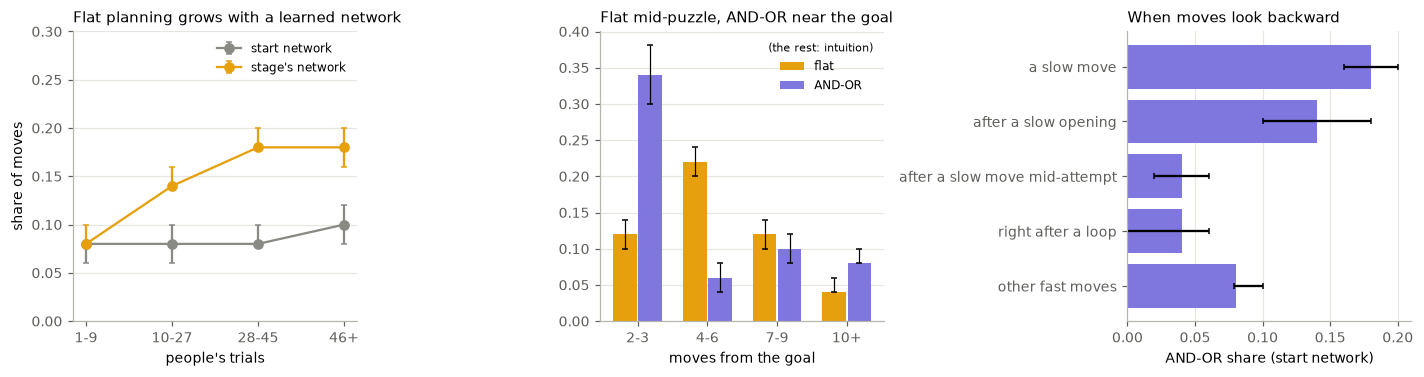

In [4]:
fit2 = pd.read_csv(os.path.join(SUMMARY, "mode_mixture", "fit.csv"))
fit3 = pd.read_csv(os.path.join(SUMMARY, "mode_mixture", "fit3.csv"))
slow_ = pd.read_csv(os.path.join(SUMMARY, "mode_mixture", "slow.csv"))
loops_ = pd.read_csv(os.path.join(SUMMARY, "mode_mixture", "loops.csv"))
STAGES = list(fm.SNAP_STAGES)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for version, color in [("start network", "#8a8a85"), ("stage's network", "#e6a00d")]:
    d = fit2[(fit2.version == version) & (fit2.moves == "all")].set_index("stage").loc[STAGES]
    axes[0].errorbar(range(4), d.w, yerr=[d.w - d["w lo"], d["w hi"] - d.w], fmt="o-", color=color, capsize=2,
                     label=version)
axes[0].set_xticks(range(4), STAGES)
axes[0].set_xlabel("people's trials")
axes[0].set_ylabel("share of moves")
axes[0].set_ylim(0, 0.3)
axes[0].set_title("Flat planning grows with a learned network")
axes[0].legend()
d = fit3[(fit3.version == "start network") & (fit3.by == "dist")].set_index("level").loc[["2-3", "4-6", "7-9", "10+"]]
xs = np.arange(4)
for comp, color, dx in [("flat", "#e6a00d", -0.18), ("AND-OR", "#7f77dd", 0.18)]:
    w = d[f"w {comp}"]
    axes[1].bar(xs + dx, w, 0.34, color=color, label=comp, yerr=[w - d[f"w {comp} lo"], d[f"w {comp} hi"] - w],
                capsize=2, error_kw={"lw": 0.8})
axes[1].set_xticks(xs, d.index)
axes[1].set_xlabel("moves from the goal")
axes[1].set_title("Flat mid-puzzle, AND-OR near the goal")
axes[1].legend(title="(the rest: intuition)", title_fontsize=7)
ROWS = [(slow_, "after slow", ("slow", "all", "all"), "a slow move"),
        (slow_, "after slow", ("1", "opener", "opening"), "after a slow opening"),
        (slow_, "after slow", ("1", "opener", "mid-attempt"), "after a slow move mid-attempt"),
        (loops_, "after loop", ("1", "all", "all"), "right after a loop"),
        (slow_, "after slow", ("other fast", "all", "all"), "other fast moves")]
for i, (t, key, idx, label) in enumerate(ROWS):
    r = t[t.version == "start network"].set_index([key, "breakdown", "level"]).loc[idx]
    axes[2].barh(i, r["w AND-OR"], color="#7f77dd", xerr=[[r["w AND-OR"] - r["w AND-OR lo"]],
                                                          [r["w AND-OR hi"] - r["w AND-OR"]]], capsize=2)
axes[2].set_yticks(range(len(ROWS)), [r[3] for r in ROWS])
axes[2].invert_yaxis()
axes[2].set_xlabel("AND-OR share (start network)")
axes[2].set_title("When moves look backward")
for ax in axes:
    tidy(ax, "y" if ax is not axes[2] else "x")
plt.tight_layout()
plt.show()

- **Intuition is the base**: 76-88% of moves in every breakdown.
- **Flat planning grows with practice, but only with a learned evaluator**: 8% → 18% of moves with each stage's network
  (it rose for 27 of 37 people); with the start network it stays at 8-10%. It peaks mid-puzzle and lives in fast moves - a quick
  "propose a few, pick the one that looks closest", used more as the evaluator becomes worth consulting.
- **AND-OR is about a tenth of moves and does not grow.** It is strongest near the goal and on **slow moves** (18%
  against 8% of other fast moves), plus the move after a slow first look at a puzzle (14%). It does **not** follow a
  loop (4%, below elsewhere: people who go in a circle retry the familiar move), and no plan is carried out after a
  slow move. People's backward reasoning looks like **one deliberated move at a time** - the paper's AND-OR model
  (one move per search), not a plan played to its end.

## 6. The lean student

*(p2.2, section 2c)* `forward.solve_lean` turns the mixture into a student: each move it draws a mode - a one-move AND-OR
deliberation (probability w_ao), flat planning (w_flat) or intuition - with the soft memory; optionally a deliberated
opening. "Lean" because it keeps only what people's moves asked for: no rollouts, no plan following.
`forward.LeanSolver` plays it in the calibrated session with the flat share rising over 30 trials, as people's did:
**with AND-OR** (flat 8% → 18%, AND-OR 10%, the opening) and **without** (flat 18% → 28%, which is what it needs to
start where people do).

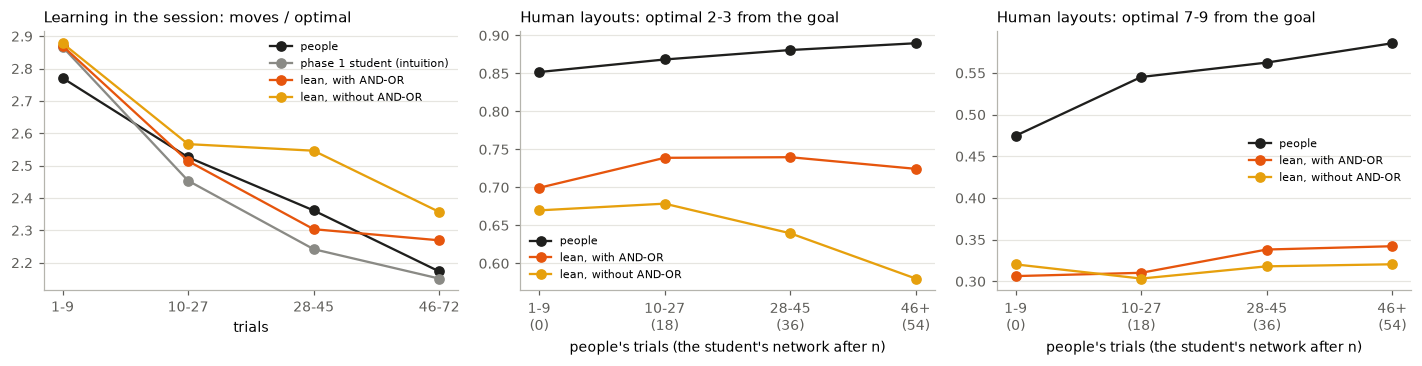

In [5]:
def session_curve(path):
    d = json.load(open(path))
    rows = []
    for lo, hi in [(1, 9), (10, 27), (28, 45), (46, 72)]:
        es = [e for r in d.values() for e in r if lo <= e["trial"] <= hi]
        won = [e for e in es if e["solved"]]
        rows.append({"trials": f"{lo}-{hi}", "solved": np.mean([e["solved"] for e in es]),
                     "moves / optimal (solved)": np.mean([e["moves"] / e["distance"] for e in won])})
    return pd.DataFrame(rows).set_index("trials")


t_people = hd.trials()
people_curve = []
for lo, hi in [(1, 9), (10, 27), (28, 45), (46, 72)]:
    g = t_people[t_people.trial.between(lo, hi)]
    w = g[g.solved]
    people_curve.append({"trials": f"{lo}-{hi}", "solved": g.groupby("subject").solved.mean().mean(),
                         "moves / optimal (solved)": (w.moves / w.distance).groupby(w.subject).mean().mean()})
curves = {"people": pd.DataFrame(people_curve).set_index("trials"),
          "phase 1 student (intuition)": session_curve(os.path.join(fm.ARCHIVE_RUN, "sessions.json")),
          "lean, with AND-OR": session_curve(os.path.join(paths.SESSIONS, "lean_people_all_m10_ao", "no_teacher",
                                                         "sessions.json")),
          "lean, without AND-OR": session_curve(os.path.join(paths.SESSIONS, "lean_people_all_m10_noao", "no_teacher",
                                                            "sessions.json"))}
paired, speople = {}, None
for name, run in [("lean, with AND-OR", "lean_people_all_m10_ao"), ("lean, without AND-OR", "lean_people_all_m10_noao")]:
    f, speople = fm.summarize_learning(pd.read_csv(os.path.join(SUMMARY, f"lean_snapshots_{run}.csv")), fm.SNAP_STAGES)
    paired[name] = f[[r.snapshot == fm.SNAP_OF[r.stage] for r in f.itertuples()]].set_index("stage")
C = {"people": PEOPLE, "phase 1 student (intuition)": "#8a8a85", "lean, with AND-OR": "#e6550d",
     "lean, without AND-OR": "#e6a00d"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for name, d in curves.items():
    axes[0].plot(range(4), d["moves / optimal (solved)"], "o-", color=C[name], label=name)
axes[0].set_xticks(range(4), curves["people"].index)
axes[0].set_xlabel("trials")
axes[0].set_title("Learning in the session: moves / optimal")
axes[0].legend(fontsize=7)
for ax, col, title in [(axes[1], "optimal 2-3", "Human layouts: optimal 2-3 from the goal"),
                       (axes[2], "optimal 7-9", "Human layouts: optimal 7-9 from the goal")]:
    ax.plot(range(4), speople.loc[STAGES, col], "o-", color=PEOPLE, label="people")
    for name, d in paired.items():
        ax.plot(range(4), d.loc[STAGES, col], "o-", color=C[name], label=name)
    ax.set_xticks(range(4), [f"{s}\n({n})" for s, n in fm.SNAP_OF.items()])
    ax.set_xlabel("people's trials (the student's network after n)")
    ax.set_title(title)
    ax.legend(fontsize=7)
for ax in axes:
    tidy(ax)
plt.tight_layout()
plt.show()

- **With AND-OR the lean student learns like people**: 2.87 → 2.27 moves / optimal over the session (people 2.77 →
  2.17), as well as phase 1's student, which was fitted to that curve - while also planning. **Without AND-OR it
  stalls** mid-session and loses accuracy near the goal as its flat share climbs. AND-OR earns its place, not as a
  solver but as occasional deliberated moves that let the flat share start low and rise.
- **The gap that remains is mid-puzzle skill**: every model so far, the lean student included, stays at 30-34% optimal
  7-9 moves from the goal on people's layouts, while people go 48% → 59%. And all of them find the human layouts
  harder than people do (2.8-3.7 moves / optimal against 1.9-2.3), while matching people on the session's puzzles.

## 7. Where this leaves the student

| | phase 1's student | the lean student |
|---|---|---|
| choosing a move | a policy sample, every move | a policy sample on most moves; flat planning (top 5 moves, value head) on 8% → 18%; a one-move AND-OR deliberation on 10%, and on the first move of an attempt |
| memory of where it has been | never back to the last 10 boards | a soft, fading penalty fitted to people's revisits |
| what AND-OR does | teaches it in pretraining | the same, plus occasional single deliberated moves |
| starts where people do | yes (misfit 0.1) | yes (0.0-1.2) |
| learns like people | yes (fitted) | yes, with AND-OR |
| human-like move by move | no revisits; no planning | revisits like people; mixes modes as people's moves suggest |

**Open questions**, in order:
1. **Mid-puzzle skill**, the gap no model closes. Candidates: training the value head on the student's own flat
   choices; a rule for *when* each mode is used (the policy's uncertainty, the blocking chain people can see) instead
   of fixed odds; a flat share tied to how reliable the evaluator has become (Daw et al. 2005) rather than a
   schedule.
2. **What triggers a slow, deliberated move** - not a loop; the opening is one trigger.
3. **The teachers again**: phase 1's teachers (bayes4) were compared on the intuition student. Help that shows a move
   lands differently on a student that sometimes plans: does bayes4 still help, and does agency (ΔA) still decide
   when help pays?

**Papers this phase drew on**: Olieslagers et al. 2023 (AND-OR; people's data); van Opheusden et al. 2023 (expertise
as deeper search); Collins et al. 2026 (novices plan flat and fast); Zhang et al. 2025 (the network decides what is
considered); Lipovetzky & Geffner (width-based novelty); Daw, Niv & Dayan 2005, Lee et al. 2014, Keramati et al.
2011/2016, Kool et al. 2017, Lieder & Griffiths 2017, Callaway et al. 2022 (arbitration and metareasoning); Newell &
Simon 1972, Anzai & Simon 1979 (means-ends analysis; strategies shifting with practice).